## Final Problem Solutions

### 3.1 A Map of Science

Where does science come from?

1. Read the file pubmed_results.txt, and extract all the US ZIP codes

In [15]:
import re

text = open("pubmed_results.txt").read()

#I used this one but I realized there are more numbers in the document, so I re did it so that find numbers all the time inside directions
#zipCodes = re.findall(r"\d{5}", text)
#so after the state which is two letters and a space, find the number of 5 digits and print it, which corresponds to zip codes.
zipCodes = re.findall(r"[A-Z]{2} (\d{5})", text)

print(zipCodes[:5])

['02138', '02115', '02138', '02138', '02138']


2. Create the lists zip_code, zip_long, zip_lat, and zip_count, containing the unique ZIP codes, their longitudes, latitudes, and counts (number of occurrences in Science), respectively. Hint: Use the csv module to parse the zipcodes_coordinates.txt.

In [9]:
import csv

#for counting the unique zip codes I'm going to do it creating a dictionary

zip_frequency = {}

for code in zipCodes:
    if code in zip_frequency:
        zip_frequency[code] += 1
    else:
        zip_frequency[code] = 1

# and in here I'm going to create the other lists but also making them correspond with the zip codes found in the articles from science

zip_code = []
zip_lat = []
zip_long = []
zip_count = []

with open("zipcodes_coordinates.txt") as file:
    reader = csv.reader(file)
    next(reader)  # Skip headers and start counting after them

    for row in reader:
        code = row[0]

        #i used float because it's necessary to convert coordenates into decimals and that will help me to do it
        if code in zip_frequency:
            zip_code.append(code)
            zip_lat.append(float(row[1]))
            zip_long.append(float(row[2]))
            #to make sure the codes I'm counting match with the document that includes science articles.
            zip_count.append(zip_frequency[code])

print(zip_code[:5])
print(zip_lat[:5])
print(zip_long[:5])
print(zip_count[:5])

['01002', '01003', '01605', '01609', '01610']
[42.364061, 42.389941, 42.289683, 42.285114, 42.247049]
[-72.458739, -72.524108, -71.787793, -71.829987, -71.808366]
[2, 4, 41, 2, 2]


3. To visualize the data you've generated, use the following code (you can copy and paste this from GitHub):

In [12]:
#I googled the error and I found the suggestion of installing this because apparently we don't have it by default
#this action solved the problem!
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 3.8 MB/s  0:00:02m0:00:0100:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 5.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 6.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


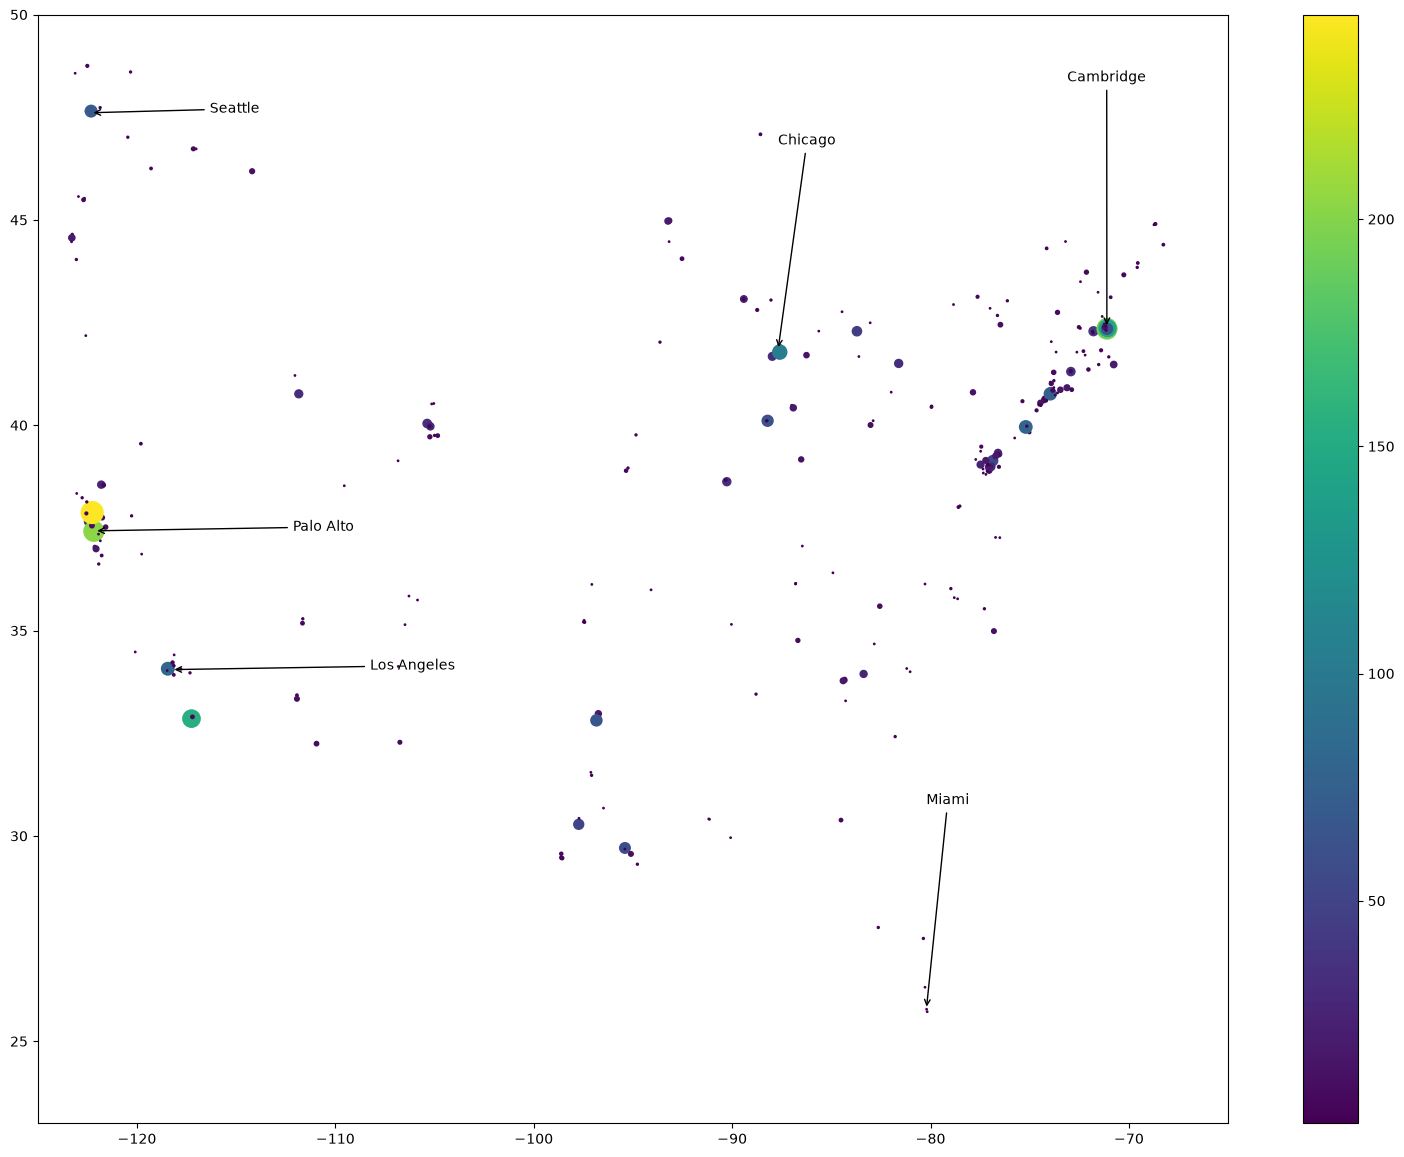

In [14]:
import matplotlib.pyplot as plt
    
# let plots be produced within the IPython notebook
%matplotlib inline

plt.scatter(zip_long, zip_lat, s = zip_count, c= zip_count)
plt.colorbar()

# only continental us without Alaska
plt.xlim(-125,-65)
plt.ylim(23, 50)

# add a few cities for reference (optional)
ard = dict(arrowstyle="->")
plt.annotate('Los Angeles', xy = (-118.25, 34.05), 
                   xytext = (-108.25, 34.05), arrowprops = ard)
plt.annotate('Palo Alto', xy = (-122.1381, 37.4292), 
                   xytext = (-112.1381, 37.4292), arrowprops= ard)
plt.annotate('Cambridge', xy = (-71.1106, 42.3736), 
                   xytext = (-73.1106, 48.3736), arrowprops= ard)
plt.annotate('Chicago', xy = (-87.6847, 41.8369), 
                   xytext = (-87.6847, 46.8369), arrowprops= ard)
plt.annotate('Seattle', xy = (-122.33, 47.61), 
                   xytext = (-116.33, 47.61), arrowprops= ard)
plt.annotate('Miami', xy = (-80.21, 25.7753), 
                   xytext = (-80.21, 30.7753), arrowprops= ard)

params = plt.gcf()
plSize = params.get_size_inches()
params.set_size_inches( (plSize[0] * 3, plSize[1] * 3) )

plt.show()